In [ ]:
import pandas as pd
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
df = pd.read_csv('data/femur_data.csv')
df.head()

,length,height
0,35.0,145.751662
1,36.5,154.819895
2,38.0,147.451499
3,39.5,154.532704
4,41.0,166.174503


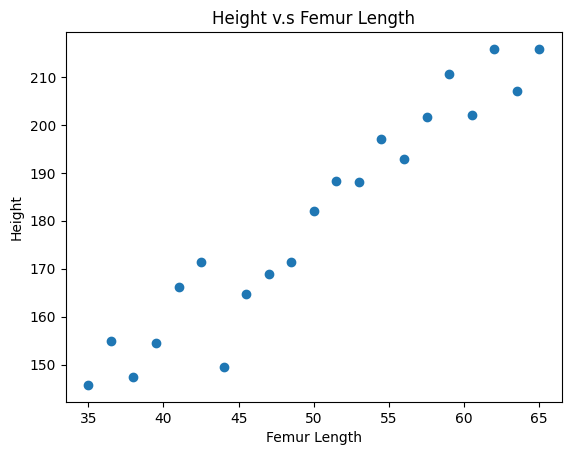

In [24]:
fig, ax = plt.subplots()

ax.plot(df['length'], df['height'], marker='o', linestyle='')
ax.set_ylabel('Height')
ax.set_xlabel('Femur Length')
ax.set_title('Height v.s Femur Length')
plt.show()

In [25]:
## ordinary least squares approach (simple linear regression)
def estimate(x, y):
    n = len(x) 
    b1_num = (np.dot(x,y) - n * np.mean(x) * np.mean(y))
    b1_den = (np.dot(x,x) - n * np.mean(x) * np.mean(x))
    b1 = b1_num / b1_den
    b0 = np.mean(y) - b1 * np.mean(x) 
    return b0, b1

def model(b0, b1, x):
    return b0 + b1 * x

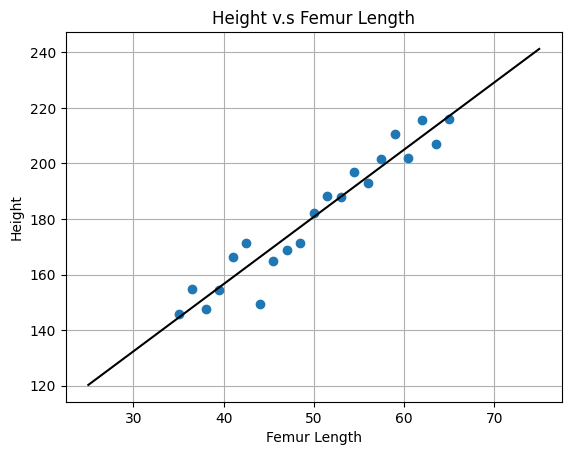

In [26]:
X, Y = np.array(df['length']), np.array(df['height'])
b0, b1 = estimate(X, Y)

x_low, x_high = np.min(X), np.max(X)
x = np.linspace(x_low - 10, x_high + 10, 200)
fig, ax = plt.subplots()
ax.plot(df['length'], df['height'], marker='o', linestyle='')
ax.plot(x, model(b0, b1, x), color='black')
ax.set_ylabel('Height')
ax.set_xlabel('Femur Length')
ax.set_title('Height v.s Femur Length')
ax.grid(True)
plt.show()

In [27]:
## sklearn approach 
from sklearn.linear_model import LinearRegression

def prep_data(df, target_col):
    X = np.array(df.drop(columns=target_col))
    y = np.array(df[target_col]).reshape((len(df[target_col]), 1))
    return X, y 

def fit_model(X, y):
    model = LinearRegression()
    model.fit(X, y)
    return model

def predict(X_pred, model):
    X_pred = np.array(X_pred)
    
    if X_pred.ndim == 1:
        if hasattr(model, "n_features_in_") and model.n_features_in_ == 1:
            X_pred = X_pred.reshape(-1, 1)
        else:
            X_pred = X_pred.reshape(1, -1)
            
    y_pred = model.predict(X_pred)
    return y_pred

In [34]:
## statsmodels 
import statsmodels.formula.api as sm

sm_model = sm.ols('height ~ length', data=df).fit()

def sm_reg(lin_model, x):
    b0 = lin_model.params.get('Intercept')
    b1 = lin_model.params.get('length')
    return b0 + b1 * x

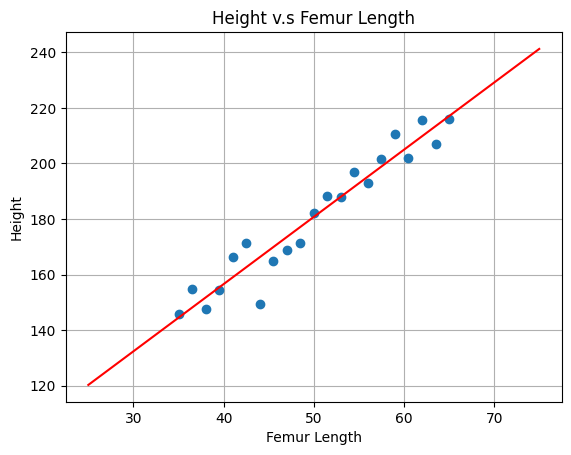

In [ ]:
X, Y = np.array(df['length']), np.array(df['height'])
b0, b1 = estimate(X, Y)

x_low, x_high = np.min(X), np.max(X)
x = np.linspace(x_low - 10, x_high + 10, 200)
fig, ax = plt.subplots()
ax.plot(df['length'], df['height'], marker='o', linestyle='', color='red')
ax.plot(x, sm_reg(sm_model, x), color='blue')
ax.set_ylabel('Height')
ax.set_xlabel('Femur Length')
ax.set_title('Height v.s Femur Length')
ax.grid(True)
plt.show()